In [1]:
!pip install -q medmnist opencv-python scikit-image scikit-learn

REG_NO = "017"

SEED = int(REG_NO[-2:])
LAST_DIGIT = int(REG_NO[-1])
HOG_CELL = 8 if LAST_DIGIT % 2 == 0 else 16
GRID = 4 if LAST_DIGIT <= 4 else 6

print("Seed      :", SEED)
print("HOG cell  :", HOG_CELL, "x", HOG_CELL)
print("SIFT grid :", GRID, "x", GRID, "=", GRID * GRID, "keypoints")

Seed      : 17
HOG cell  : 16 x 16
SIFT grid : 6 x 6 = 36 keypoints


In [2]:
import random, warnings
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

random.seed(SEED); np.random.seed(SEED)

IMG = 128
KEEP = [1, 5, 6, 7]                                    # BloodMNIST label ids
NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER = {"train": 100, "val": 30, "test": 30}
print("OpenCV", cv2.__version__, "| SIFT available:", hasattr(cv2, "SIFT_create"))

OpenCV 5.0.0 | SIFT available: True


# Question No 1: **Data setup**

In [3]:
from medmnist import BloodMNIST

raw = {s: BloodMNIST(split=s, download=True, size=64) for s in ["train", "val", "test"]}
for s, d in raw.items():
    print(s, "full split:", d.imgs.shape, "labels:", d.labels.shape)

100%|██████████| 156M/156M [00:15<00:00, 9.97MB/s]


train full split: (11959, 64, 64, 3) labels: (11959, 1)
val full split: (1712, 64, 64, 3) labels: (1712, 1)
test full split: (3421, 64, 64, 3) labels: (3421, 1)


In [4]:
def prep(rgb):
    """RGB uint8 (64x64x3) -> grayscale uint8 128x128."""
    g = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (IMG, IMG), interpolation=cv2.INTER_LINEAR)

rng = np.random.RandomState(SEED)                      # one RNG, fixed order -> reproducible
data, rgb_keep = {}, {}
for split in ["train", "val", "test"]:
    imgs, labels = raw[split].imgs, raw[split].labels.ravel()
    sel = []
    for new_id, old_id in enumerate(KEEP):
        idx = np.where(labels == old_id)[0]
        pick = rng.choice(idx, N_PER[split], replace=False)
        sel += [(i, new_id) for i in pick]
    order = rng.permutation(len(sel))                  # shuffle the subset (seeded)
    sel = [sel[k] for k in order]
    rgb_keep[split] = np.stack([imgs[i] for i, _ in sel])
    X = np.stack([prep(imgs[i]) for i, _ in sel])
    y = np.array([c for _, c in sel])
    data[split] = (X, y)

for split, (X, y) in data.items():
    print(f"{split:5s} X shape = {X.shape}, dtype={X.dtype}, y shape = {y.shape}")
    print("      class counts:", {NAMES[c]: int((y == c).sum()) for c in range(4)})

train X shape = (400, 128, 128), dtype=uint8, y shape = (400,)
      class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   X shape = (120, 128, 128), dtype=uint8, y shape = (120,)
      class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  X shape = (120, 128, 128), dtype=uint8, y shape = (120,)
      class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


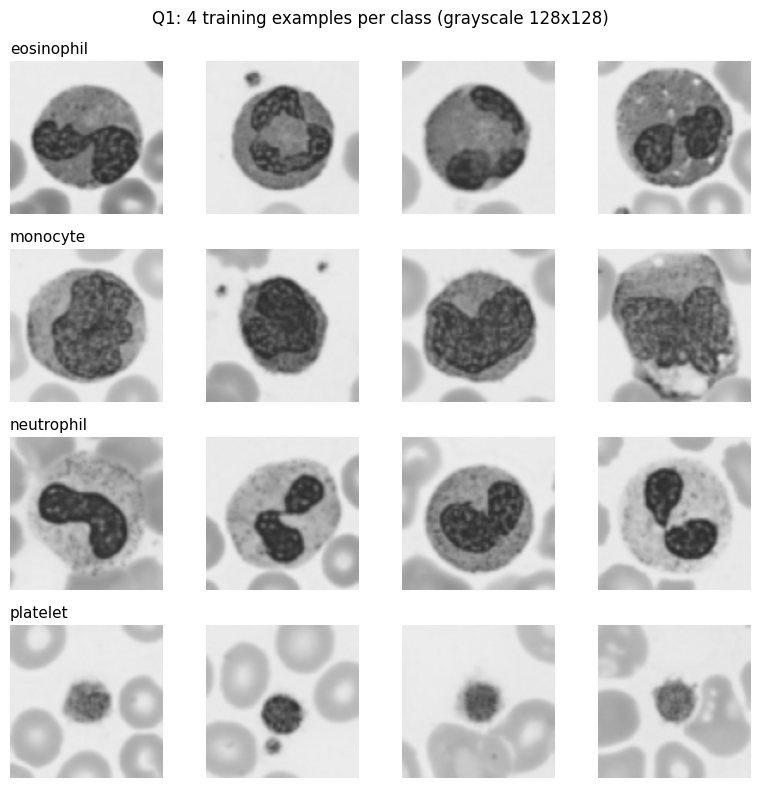

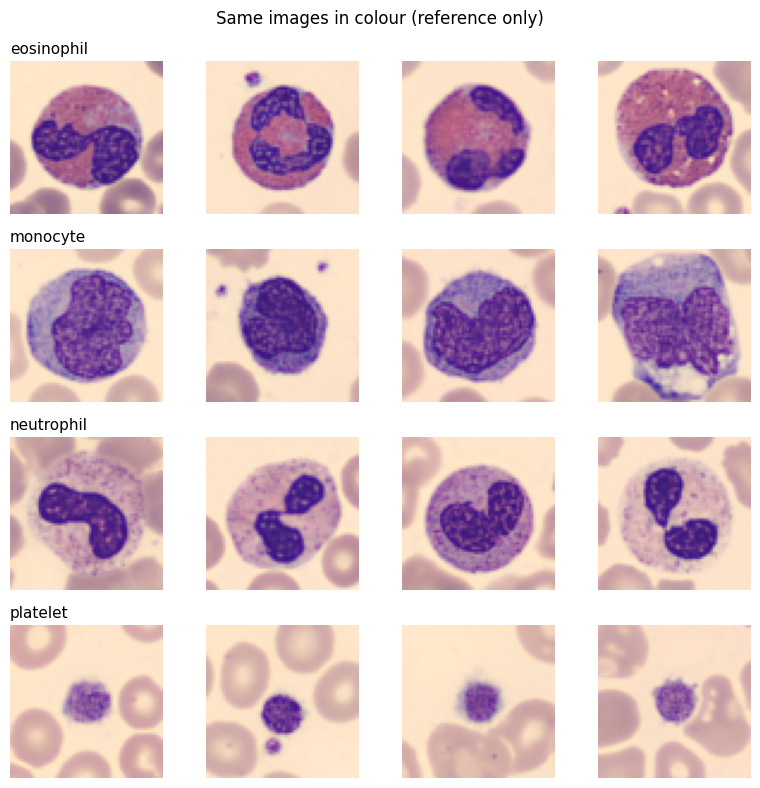

In [5]:
# One grid with 4 example images per class (the grayscale 128x128 images the models see)
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
Xtr, ytr = data["train"]
for r in range(4):
    ids = np.where(ytr == r)[0][:4]
    for c in range(4):
        ax[r, c].imshow(Xtr[ids[c]], cmap="gray", vmin=0, vmax=255); ax[r, c].axis("off")
    ax[r, 0].set_title(NAMES[r], loc="left", fontsize=11)
plt.suptitle("Q1: 4 training examples per class (grayscale 128x128)"); plt.tight_layout(); plt.show()

# Same images in colour (for Q5, to see what grayscale throws away)
fig, ax = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    ids = np.where(ytr == r)[0][:4]
    for c in range(4):
        ax[r, c].imshow(rgb_keep["train"][ids[c]]); ax[r, c].axis("off")
    ax[r, 0].set_title(NAMES[r], loc="left", fontsize=11)
plt.suptitle("Same images in colour (reference only)"); plt.tight_layout(); plt.show()

### Helper functions (used by Q2, Q3, Q4)

In [6]:
Cs = [0.1, 1, 10]
Xtr, ytr = data["train"]; Xva, yva = data["val"]; Xte, yte = data["test"]

def make_svm(C):
    # scaler is fitted on training features only; LinearSVC is the required classifier
    return make_pipeline(StandardScaler(), LinearSVC(C=C, dual=True, max_iter=50000, random_state=SEED))

def choose_C(Ftr, ytr, Fva, yva, label):
    rows, best = [], None
    for C in Cs:
        m = make_svm(C).fit(Ftr, ytr)
        acc = accuracy_score(yva, m.predict(Fva))
        rows.append((C, acc))
        if best is None or acc > best[1]:               # ties keep the smaller C
            best = (C, acc, m)
    print(f"{label}: validation accuracy for each C")
    print(pd.DataFrame(rows, columns=["C", "val_accuracy"]).to_string(index=False))
    print("-> chosen C =", best[0])
    return best[0], best[2]

def report(model, F, y, label):
    pred = model.predict(F)
    acc = accuracy_score(y, pred)
    f1 = f1_score(y, pred, average="macro")
    cm = confusion_matrix(y, pred, labels=range(4))
    print(f"{label}: accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted; order:", NAMES, ")")
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(label); plt.show()
    return acc, f1, cm

### Question No 2(a) HOG features and feature length by hand

In [7]:
def hog_feat(g, visualize=False):
    return hog(g, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys",
               visualize=visualize, feature_vector=True)

def extract(imgs, fn):
    return np.array([fn(g) for g in imgs])

Htr, Hva = extract(Xtr, hog_feat), extract(Xva, hog_feat)
print("HOG feature matrices:", Htr.shape, Hva.shape)
print("HOG feature length per image:", Htr.shape[1])

# the hand calculation, done in code to double-check it
cells = IMG // HOG_CELL
blocks = cells - 2 + 1
per_block = 2 * 2 * 9
print(f"cells per side = {IMG}/{HOG_CELL} = {cells}; blocks per side = {cells}-2+1 = {blocks}")
print(f"values per block = 2*2*9 = {per_block}; total = {blocks}*{blocks}*{per_block} = {blocks*blocks*per_block}")
assert blocks * blocks * per_block == Htr.shape[1]

HOG feature matrices: (400, 1764) (120, 1764)
HOG feature length per image: 1764
cells per side = 128/16 = 8; blocks per side = 8-2+1 = 7
values per block = 2*2*9 = 36; total = 7*7*36 = 1764


### Question No 2(b) HOG pictures, one image per class

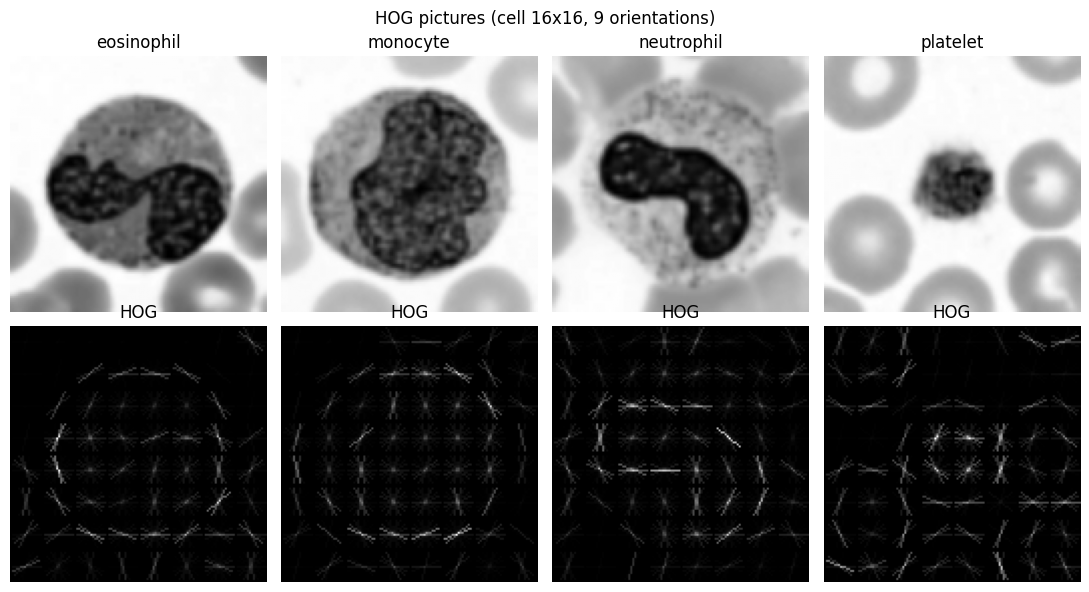

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(11, 6))
for c in range(4):
    i = np.where(ytr == c)[0][0]
    _, hog_img = hog_feat(Xtr[i], visualize=True)
    ax[0, c].imshow(Xtr[i], cmap="gray"); ax[0, c].set_title(NAMES[c]); ax[0, c].axis("off")
    ax[1, c].imshow(exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-9)), cmap="gray")
    ax[1, c].set_title("HOG"); ax[1, c].axis("off")
plt.suptitle(f"HOG pictures (cell {HOG_CELL}x{HOG_CELL}, 9 orientations)"); plt.tight_layout(); plt.show()

### Question No 2(c) Train HOG + SVM, choose C on validation

HOG + SVM: validation accuracy for each C
   C  val_accuracy
 0.1      0.758333
 1.0      0.758333
10.0      0.758333
-> chosen C = 0.1
HOG + SVM (validation): accuracy = 0.7583 | macro-F1 = 0.7561
Confusion matrix (rows = true, cols = predicted; order: ['eosinophil', 'monocyte', 'neutrophil', 'platelet'] )
[[19  8  3  0]
 [ 4 22  3  1]
 [ 6  3 20  1]
 [ 0  0  0 30]]


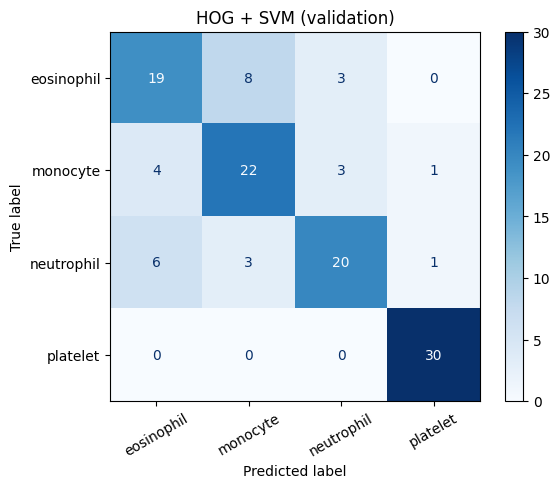

In [9]:
C_hog, hog_model = choose_C(Htr, ytr, Hva, yva, "HOG + SVM")
hog_val_acc, hog_val_f1, hog_val_cm = report(hog_model, Hva, yva, "HOG + SVM (validation)")

### Question No 3(a) Normal SIFT detection on the training images

Keypoints per image -> average: 72.00 | min: 11 | max: 184
Images with zero keypoints: 0 of 400


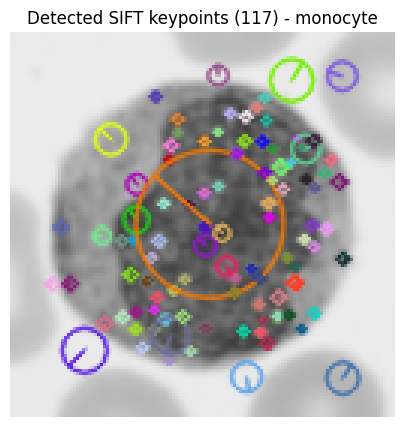

In [10]:
sift = cv2.SIFT_create()
counts, kp_store = [], []
for g in Xtr:
    kps, desc = sift.detectAndCompute(g, None)
    counts.append(len(kps)); kp_store.append(kps)
counts = np.array(counts)
print(f"Keypoints per image -> average: {counts.mean():.2f} | min: {counts.min()} | max: {counts.max()}")
print("Images with zero keypoints:", int((counts == 0).sum()), "of", len(counts))

i = int(np.argmax(counts > 0)) if (counts > 0).any() else 0
vis = cv2.drawKeypoints(Xtr[i], kp_store[i], None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"Detected SIFT keypoints ({len(kp_store[i])}) - {NAMES[ytr[i]]}"); plt.show()

### Question No 3(b) Fixed grid of keypoints

SIFT-grid feature matrices: (400, 4608) (120, 4608)
SIFT feature length per image: 4608
Check: 36 grid points x 128 = 4608


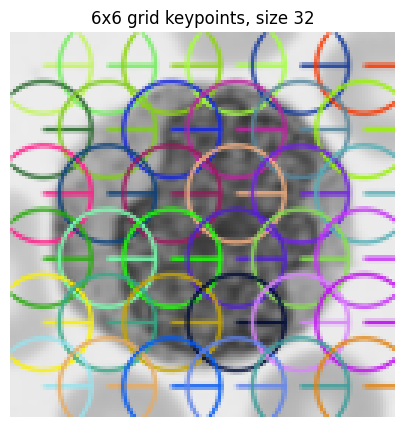

In [11]:
def grid_keypoints(grid=GRID, size=32):
    step = IMG / grid
    centres = (np.arange(grid) + 0.5) * step            # evenly spread over 128 x 128
    # angle=0 is set explicitly so every image uses the same (upright) orientation
    return [cv2.KeyPoint(float(x), float(y), float(size), 0.0) for y in centres for x in centres]

GRID_KPS = grid_keypoints()

def sift_feat(g):
    _, desc = sift.compute(g, GRID_KPS)
    assert desc is not None and desc.shape == (GRID * GRID, 128), "descriptor shape problem"
    return desc.reshape(-1)

Str, Sva = extract(Xtr, sift_feat), extract(Xva, sift_feat)
print("SIFT-grid feature matrices:", Str.shape, Sva.shape)
print("SIFT feature length per image:", Str.shape[1])
print(f"Check: {GRID*GRID} grid points x 128 = {GRID*GRID*128}")

vis = cv2.drawKeypoints(Xtr[0], GRID_KPS, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title(f"{GRID}x{GRID} grid keypoints, size 32"); plt.show()

### Question No 3(c) Train SIFT + SVM, choose C on validation

SIFT + SVM: validation accuracy for each C
   C  val_accuracy
 0.1      0.708333
 1.0      0.700000
10.0      0.700000
-> chosen C = 0.1
SIFT + SVM (validation): accuracy = 0.7083 | macro-F1 = 0.7013
Confusion matrix (rows = true, cols = predicted; order: ['eosinophil', 'monocyte', 'neutrophil', 'platelet'] )
[[16  9  4  1]
 [ 4 24  1  1]
 [ 8  7 15  0]
 [ 0  0  0 30]]


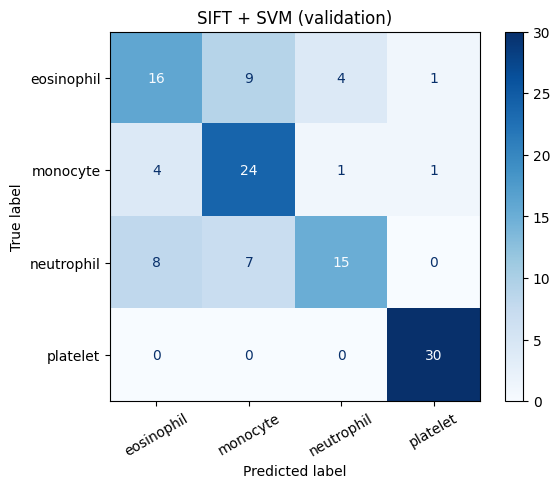

In [12]:
C_sift, sift_model = choose_C(Str, ytr, Sva, yva, "SIFT + SVM")
sift_val_acc, sift_val_f1, sift_val_cm = report(sift_model, Sva, yva, "SIFT + SVM (validation)")

### Question No 4(a) Prediction, written BEFORE running the test

In [13]:
# Prediction, locked in before the test set is used.  Change to "SIFT" if that is your own view.
PRED_ROTATION = "HOG"
PRED_NOISE = "HOG"
print("Prediction -> rotation: ", PRED_ROTATION, "| noise:", PRED_NOISE)

Prediction -> rotation:  HOG | noise: HOG


### Question No 4(b) Frozen models evaluated on the test set

In [14]:
def rotate(g, angle=20):
    M = cv2.getRotationMatrix2D((IMG / 2, IMG / 2), angle, 1.0)
    return cv2.warpAffine(g, M, (IMG, IMG), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)

def add_noise(g, sigma=0.05, rs=None):
    x = g.astype(np.float32) / 255.0                    # scale to 0..1
    x = np.clip(x + rs.normal(0, sigma, x.shape), 0, 1)
    return np.round(x * 255).astype(np.uint8)

noise_rs = np.random.RandomState(SEED)
Xte_rot = np.stack([rotate(g) for g in Xte])
Xte_noisy = np.stack([add_noise(g, rs=noise_rs) for g in Xte])

# the change is applied to the IMAGES, then features are extracted again
cases = {"Clean": Xte, "Rotated": Xte_rot, "Noisy": Xte_noisy}
models = {"HOG + SVM": (hog_model, hog_feat), "SIFT + SVM": (sift_model, sift_feat)}

res = {}
for name, (model, fn) in models.items():            # models are frozen: only predict()
    res[name] = {case: accuracy_score(yte, model.predict(extract(imgs, fn))) for case, imgs in cases.items()}

table = pd.DataFrame(res).T[["Clean", "Rotated", "Noisy"]]
table.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
print(table.round(4).to_string())
table.round(4)

            Clean accuracy  Rotated accuracy  Noisy accuracy
HOG + SVM           0.7333            0.6917          0.2500
SIFT + SVM          0.7167            0.7500          0.7083


,Clean accuracy,Rotated accuracy,Noisy accuracy
HOG + SVM,0.7333,0.6917,0.2500
SIFT + SVM,0.7167,0.7500,0.7083


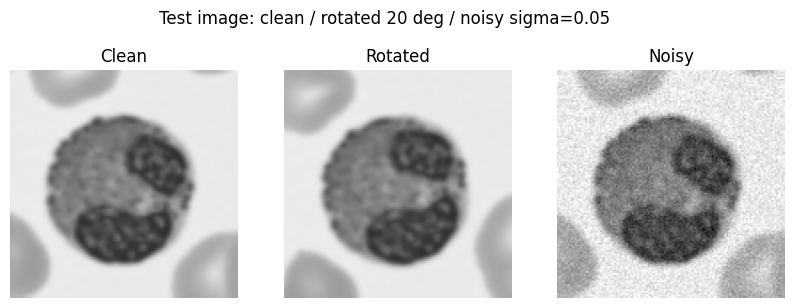

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a, (case, imgs) in zip(ax, cases.items()):
    a.imshow(imgs[0], cmap="gray", vmin=0, vmax=255); a.set_title(case); a.axis("off")
plt.suptitle("Test image: clean / rotated 20 deg / noisy sigma=0.05"); plt.show()

### Question No 4(c) Was the prediction correct?  - the text below is generated from the table

In [16]:
t = table.copy()
drop_rot = (t["Clean accuracy"] - t["Rotated accuracy"])
drop_noise = (t["Clean accuracy"] - t["Noisy accuracy"])
short = {"HOG + SVM": "HOG", "SIFT + SVM": "SIFT"}
lost_rot = short[drop_rot.idxmax()]
lost_noise = short[drop_noise.idxmax()]

print("Accuracy drop (clean - changed):")
print(pd.DataFrame({"rotation drop": drop_rot, "noise drop": drop_noise}).round(4).to_string())
print()
ok_r, ok_n = (PRED_ROTATION == lost_rot), (PRED_NOISE == lost_noise)
print(f"Sentence 1: Under rotation HOG fell by {drop_rot['HOG + SVM']*100:.1f} points and SIFT by {drop_rot['SIFT + SVM']*100:.1f} points, "
      f"so {lost_rot} lost more; under noise HOG fell by {drop_noise['HOG + SVM']*100:.1f} points and SIFT by {drop_noise['SIFT + SVM']*100:.1f} points, so {lost_noise} lost more.")
print(f"Sentence 2: My rotation prediction ({PRED_ROTATION}) was {'correct' if ok_r else 'wrong'} and my noise prediction ({PRED_NOISE}) was {'correct' if ok_n else 'wrong'}.")

why_rot = {"HOG": "HOG's 20-degree-wide orientation bins and fixed cell layout shift when the image turns",
           "SIFT": "the grid SIFT descriptors are computed with a fixed angle of 0, so they are not rotation-invariant and the grid points land on different content"}
why_noise = {"HOG": "HOG takes gradients directly from raw pixels, so noise adds random gradient energy in every cell",
             "SIFT": "SIFT descriptors use small-scale gradients, so the added noise changes many descriptor bins"}
print(f"Sentence 3: A likely reason is that {why_rot[lost_rot]}, and for noise that {why_noise[lost_noise]}.")

Accuracy drop (clean - changed):
            rotation drop  noise drop
HOG + SVM          0.0417      0.4833
SIFT + SVM        -0.0333      0.0083

Sentence 1: Under rotation HOG fell by 4.2 points and SIFT by -3.3 points, so HOG lost more; under noise HOG fell by 48.3 points and SIFT by 0.8 points, so HOG lost more.
Sentence 2: My rotation prediction (HOG) was correct and my noise prediction (HOG) was correct.
Sentence 3: A likely reason is that HOG's 20-degree-wide orientation bins and fixed cell layout shift when the image turns, and for noise that HOG takes gradients directly from raw pixels, so noise adds random gradient energy in every cell.


### Question No 5(b) Which two classes were confused most? - computed from the validation confusion matrices

In [17]:
def top_confused(cm):
    best, pair = -1, None
    for i in range(4):
        for j in range(i + 1, 4):
            n = cm[i, j] + cm[j, i]
            if n > best: best, pair = n, (i, j)
    return pair, best

for label, cm in [("HOG + SVM", hog_val_cm), ("SIFT + SVM", sift_val_cm)]:
    (i, j), n = top_confused(cm)
    if n == 0:
        print(f"{label}: no validation errors between any two classes"); continue
    print(f"{label}: most confused pair = {NAMES[i]} vs {NAMES[j]} ({n} validation errors between them: "
          f"{cm[i, j]} {NAMES[i]}->{NAMES[j]} and {cm[j, i]} {NAMES[j]}->{NAMES[i]})")

(i, j), n = top_confused(hog_val_cm + sift_val_cm)
print(f"\nBoth models together: {NAMES[i]} vs {NAMES[j]} ({n} errors)")

HOG + SVM: most confused pair = eosinophil vs monocyte (12 validation errors between them: 8 eosinophil->monocyte and 4 monocyte->eosinophil)
SIFT + SVM: most confused pair = eosinophil vs monocyte (13 validation errors between them: 9 eosinophil->monocyte and 4 monocyte->eosinophil)

Both models together: eosinophil vs monocyte (25 errors)
